In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dateutil.relativedelta import relativedelta

Создание исходной таблицы

In [2]:
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.float_format', '{:.2f}'.format)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Исходные данные
data = {
    '№ п/п': [1, 2, 3, 4, 5, 6],
    'Место работы': ['ООО "Альфа"', 'ООО "Бета"', 'ООО "Гамма"',
                     'ООО "Дельта"', 'ООО "Эпсилон"', 'ООО "Зета"'],
    'Дата поступления': ['2015-01-15', '2017-03-01', '2019-06-10',
                         '2021-02-01', '2022-09-01', '2024-01-10'],
    'Дата увольнения (перевода)': ['2017-02-28', '2019-05-31', '2021-01-31',
                                   '2022-08-31', '2023-12-31', '2025-06-30'],
    'Должность': ['Программист', 'Программист', 'Старший программист',
                  'Старший программист', 'Руководитель отдела', 'Руководитель отдела'],
    'Оклад': [50000, 60000, 75000, 80000, 95000, 100000]
}
df = pd.DataFrame(data)
df['Дата поступления'] = pd.to_datetime(df['Дата поступления'])
df['Дата увольнения (перевода)'] = pd.to_datetime(df['Дата увольнения (перевода)'])
df

,№ п/п,Место работы,Дата поступления,Дата увольнения (перевода),Должность,Оклад
0,1,"ООО ""Альфа""",2015-01-15,2017-02-28,Программист,50000
1,2,"ООО ""Бета""",2017-03-01,2019-05-31,Программист,60000
2,3,"ООО ""Гамма""",2019-06-10,2021-01-31,Старший программист,75000
3,4,"ООО ""Дельта""",2021-02-01,2022-08-31,Старший программист,80000
4,5,"ООО ""Эпсилон""",2022-09-01,2023-12-31,Руководитель отдела,95000
5,6,"ООО ""Зета""",2024-01-10,2025-06-30,Руководитель отдела,100000


Задача 1

In [3]:
# Стаж работы в каждой должности
df['Стаж (лет)'] = ((df['Дата увольнения (перевода)'] - df['Дата поступления']).dt.days / 365.25).round(2)
# Накопленный стаж на момент окончания данной должности
df['Общий стаж (лет)'] = df['Стаж (лет)'].cumsum().round(2)
df[['№ п/п', 'Место работы', 'Должность', 'Стаж (лет)', 'Общий стаж (лет)']]

,№ п/п,Место работы,Должность,Стаж (лет),Общий стаж (лет)
0,1,"ООО ""Альфа""",Программист,2.12,2.12
1,2,"ООО ""Бета""",Программист,2.25,4.37
2,3,"ООО ""Гамма""",Старший программист,1.65,6.02
3,4,"ООО ""Дельта""",Старший программист,1.58,7.60
4,5,"ООО ""Эпсилон""",Руководитель отдела,1.33,8.93
5,6,"ООО ""Зета""",Руководитель отдела,1.47,10.40


Задача 2

In [4]:
def bonus_percent(total_exp):
    if total_exp < 5:
        return 0.10
    elif total_exp > 10:
        return 0.20
    else:
        return 0.15
df['Надбавка (%)'] = df['Общий стаж (лет)'].apply(bonus_percent)
df['Надбавка, руб.'] = (df['Оклад'] * df['Надбавка (%)']).round(2)
df['Оплата труда'] = df['Оклад'] + df['Надбавка, руб.']
df[['№ п/п', 'Общий стаж (лет)', 'Оклад', 'Надбавка (%)',
    'Надбавка, руб.', 'Оплата труда']]

,№ п/п,Общий стаж (лет),Оклад,Надбавка (%),"Надбавка, руб.",Оплата труда
0,1,2.12,50000,0.10,5000.00,55000.00
1,2,4.37,60000,0.10,6000.00,66000.00
2,3,6.02,75000,0.15,11250.00,86250.00
3,4,7.60,80000,0.15,12000.00,92000.00
4,5,8.93,95000,0.15,14250.00,109250.00
5,6,10.40,100000,0.20,20000.00,120000.00


Задача 3

In [5]:
result = df.copy()
result['Дата поступления'] = result['Дата поступления'].dt.strftime('%d.%m.%Y')
result['Дата увольнения (перевода)'] = result['Дата увольнения (перевода)'].dt.strftime('%d.%m.%Y')
result['Надбавка (%)'] = (result['Надбавка (%)'] * 100).astype(int).astype(str) + '%'
display(result[['№ п/п', 'Место работы', 'Дата поступления',
                'Дата увольнения (перевода)', 'Должность', 'Оклад',
                'Стаж (лет)', 'Общий стаж (лет)', 'Надбавка (%)',
                'Надбавка, руб.', 'Оплата труда']])

,№ п/п,Место работы,Дата поступления,Дата увольнения (перевода),Должность,Оклад,Стаж (лет),Общий стаж (лет),Надбавка (%),"Надбавка, руб.",Оплата труда
0,1,"ООО ""Альфа""",15.01.2015,28.02.2017,Программист,50000,2.12,2.12,10%,5000.00,55000.00
1,2,"ООО ""Бета""",01.03.2017,31.05.2019,Программист,60000,2.25,4.37,10%,6000.00,66000.00
2,3,"ООО ""Гамма""",10.06.2019,31.01.2021,Старший программист,75000,1.65,6.02,15%,11250.00,86250.00
3,4,"ООО ""Дельта""",01.02.2021,31.08.2022,Старший программист,80000,1.58,7.60,15%,12000.00,92000.00
4,5,"ООО ""Эпсилон""",01.09.2022,31.12.2023,Руководитель отдела,95000,1.33,8.93,15%,14250.00,109250.00
5,6,"ООО ""Зета""",10.01.2024,30.06.2025,Руководитель отдела,100000,1.47,10.40,20%,20000.00,120000.00


Задача 4

In [6]:
# Последние 2 записи
last_two = df.tail(2).copy()
def months_inclusive(start, end):
    m = (end.year - start.year) * 12 + (end.month - start.month)
    if end.day >= start.day:
        m += 1
    return m
last_two['Месяцев'] = last_two.apply(
    lambda r: months_inclusive(r['Дата поступления'], r['Дата увольнения (перевода)']),
    axis=1
)
print(last_two[['Должность', 'Оклад', 'Оплата труда', 'Месяцев']])
total_pay = (last_two['Оплата труда'] * last_two['Месяцев']).sum()
total_months = last_two['Месяцев'].sum()
avg_2y = total_pay / total_months
print(f"\nСреднемесячная оплата труда за последние 2 года: {avg_2y:,.2f} руб.")

             Должность   Оклад  Оплата труда  Месяцев
4  Руководитель отдела   95000     109250.00       16
5  Руководитель отдела  100000     120000.00       18

Среднемесячная оплата труда за последние 2 года: 114,941.18 руб.


Задача 5

In [7]:
avg_pay = df['Оплата труда'].mean()
print(f"Средняя оплата труда по всем записям: {avg_pay:,.2f} руб.")
below = df[df['Оплата труда'] < avg_pay]
print(f"\nКоличество записей (сотрудников) с оплатой ниже средней: {len(below)}")
display(below[['№ п/п', 'Место работы', 'Должность', 'Оплата труда']])

Средняя оплата труда по всем записям: 88,083.33 руб.

Количество записей (сотрудников) с оплатой ниже средней: 3


,№ п/п,Место работы,Должность,Оплата труда
0,1,"ООО ""Альфа""",Программист,55000.00
1,2,"ООО ""Бета""",Программист,66000.00
2,3,"ООО ""Гамма""",Старший программист,86250.00


Задача 6

In [8]:
print(f"Минимальная оплата труда : {df['Оплата труда'].min():,.2f} руб.")
print(f"Максимальная оплата труда: {df['Оплата труда'].max():,.2f} руб.")

Минимальная оплата труда : 55,000.00 руб.
Максимальная оплата труда: 120,000.00 руб.


Задача 7

In [9]:
avg_by_position = (
    df.groupby('Должность', as_index=False)['Оплата труда']
      .mean()
      .rename(columns={'Оплата труда': 'Средняя оплата'})
      .sort_values('Средняя оплата')
)
display(avg_by_position)

,Должность,Средняя оплата
0,Программист,60500.00
2,Старший программист,89125.00
1,Руководитель отдела,114625.00


Задача 8

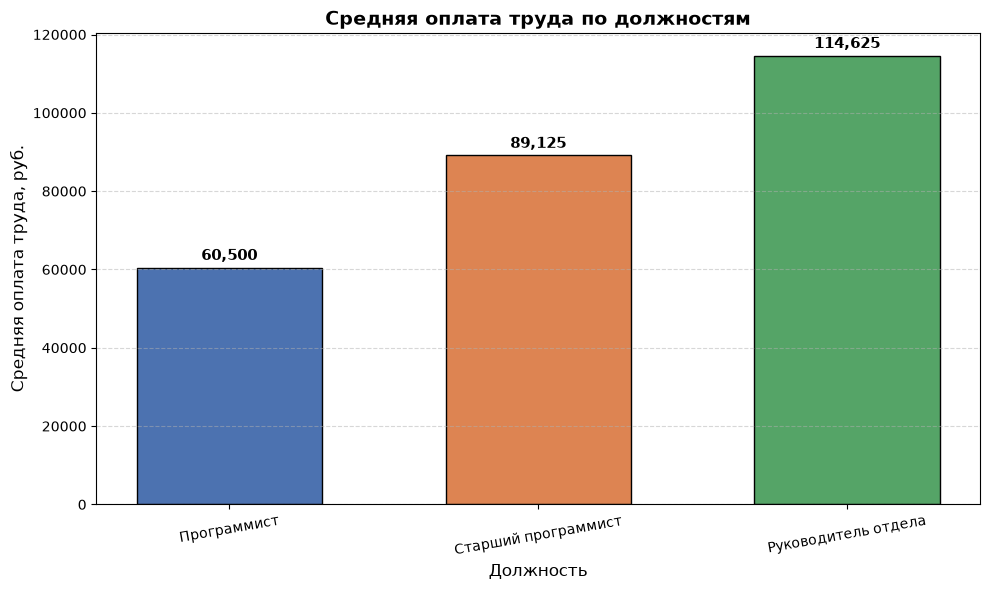

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(avg_by_position['Должность'], avg_by_position['Средняя оплата'],
              color=['#4C72B0', '#DD8452', '#55A467'], edgecolor='black', width=0.6)

for bar, val in zip(bars, avg_by_position['Средняя оплата']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
            f'{val:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_xlabel('Должность', fontsize=12)
ax.set_ylabel('Средняя оплата труда, руб.', fontsize=12)
ax.set_title('Средняя оплата труда по должностям', fontsize=14, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()